# Finite Elements for Contaminant Transport

# Problem description
In this notebook, code is provided to solve the advection/diffusion/reaction equation for transport of a contaminant in groundwater after an industrial spill. The advection/diffusion/reaction equation is given by:

$$
\frac{\partial c}{\partial t} = \kappa \nabla\cdot\nabla c - \mathbf{v}\cdot\nabla c - r c
$$

or

$$
\frac{\partial c}{\partial t} = \kappa\left(\frac{\partial^2 c}{\partial x^2}+\frac{\partial^2 c}{\partial y^2}\right) - v_x \frac{\partial c}{\partial x} - v_y \frac{\partial c}{\partial y} - rc
$$

Where 
- $c$ is the unknown concentration field, dependent on space ($x$, $y$) and time ($t$)
- $\kappa$ is the diffusivity, assumed to be constant
- $\mathbf{v}$ is the groundwater velocity, satisfying $\nabla\cdot \mathbf{v} = 0$
- $r$ is a reaction rate, representing exponential decay of the contaminant

The two-dimensional domain $\Omega$ has a boundary $\Gamma$ that can be subdivided in a part where Dirichlet boundary conditions are applied $\Gamma_D$ and a part where Neumann boundary conditions are applied $\Gamma_N$. The Neumann boundary conditions define a contaminant flux of magnitude $q(x,y,t)$ into the domain:

$$
\kappa\nabla c\cdot \mathbf{n} = q
$$

where $\mathbf{n}$ is the outward pointing normal to the boundary. 

<div style="background-color:#AABAB2; color: black; width:90%; vertical-align: middle; padding:15px; margin: 10px; border-radius: 10px">
<p>

**Task 1**

To solve the problem finite element discretization is applied in 2D space, while time is discretized with backward Euler time stepping. A semi-discrete form is obtained by applying the finite element discretization, while leaving the time derivative untouched. The semi-discrete form for this problem is: 

$$
\mathbf{M}\frac{\partial\mathbf{c}}{\partial t} + \mathbf{Kc} + \mathbf{Cc} + \mathbf{Rc} = \mathbf{f}
$$

where $\mathbf{M}$, $\mathbf{K}$, $\mathbf{C}$ and $\mathbf{R}$ are matrices and $\mathbf{c}$ is a vector with concentration values at the nodes. For now, $\mathbf{c}$ is still a continuous function of time.  

Starting from the strong form of the advection/diffusion/reaction equation, derive expressions for finite element matrices $\mathbf{M}$, $\mathbf{K}$, $\mathbf{C}$ and $\mathbf{R}$.
</p>
</div>

<div style="background-color:#facb8e; color: black; vertical-align: middle; padding:15px; margin: 10px; border-radius: 10px; width: 90%">
<p>

**Hint:**

- The matrix $\mathbf{K}$ should have the same form as the matrix for the 2D Poisson equation as derived [in the book](https://mude.citg.tudelft.nl/book/2025/fem/poisson2d.html) (except that $\kappa$ takes the place of $\nu$). 
- The concentration depends on time and space $c \equiv c(x,y,t)$. Spatial discretization is done with finite element shape functions, while time-dependence is in the nodal degrees of freedom: $c(x,y,t) = \mathbf{N}(x,y)\mathbf{c}(t)$. 
- You can check your result for all matrices by comparing the matrix definitions you arrive at against those implemented in the code in this notebook.

</p>
</div>

<div style="background-color:#FAE99E; color: black; vertical-align: middle; padding:15px; margin: 10px; border-radius: 10px; width: 90%">
<p>
<b>Solution</b>

Move everything depending on $c$ to the left hand side (can also be done in a later step), multiply with $w$ and integrate over the domain

$$
\int_\Omega w\left(\frac{\partial c}{\partial t} - \kappa\nabla\cdot\nabla c + \mathbf{v}\cdot\nabla c + r c\right) \,\mathrm{d}\Omega = 0 \quad \forall \quad w(x,y)
$$

Apply integration by parts only on the term with $\kappa$

$$
\int_\Omega w\frac{\partial c}{\partial t} + \kappa\nabla w\cdot\nabla c + w\mathbf{v}\cdot\nabla c + w r c \,\mathrm{d}\Omega - \int_\Gamma w\kappa\nabla c\cdot \mathbf{n} \,\mathrm{d}\Gamma = 0 \quad \forall \quad w(x,y)
$$

Substitution of Neumann boundary conditions and setting $w=0$ on the part of the boundary where Dirichlet boundary are applied and moving to right hand side:

$$
\int_\Omega w\frac{\partial c}{\partial t} + \kappa\nabla w\cdot\nabla c + w\mathbf{v}\cdot\nabla c + w r c \,\mathrm{d}\Omega = \int_{\Gamma_N} wq \,\mathrm{d}\Gamma  \quad \forall \quad w(x,y)
$$

Substitution of $w = \mathbf{N}\mathbf{w}$, $\nabla w = \mathbf{Bw}$, $c = \mathbf{N}\mathbf{c}$, $\nabla c = \mathbf{B}\mathbf{c}$ gives:

$$
\int_\Omega \mathbf{Nw}\frac{\partial \mathbf{Nc}}{\partial t} + \kappa\mathbf{Bw}\cdot\mathbf{Bc} + \mathbf{Nw}\mathbf{v}\cdot\mathbf{Bc} + \mathbf{Nw} r \mathbf{Nc} \,\mathrm{d}\Omega = \int_{\Gamma_N} \mathbf{Nw}q \,\mathrm{d}\Gamma  \quad \forall \quad \mathbf{w}
$$

Moving $\mathbf{w}$ and $\mathbf{c}$ out of the integral, removing $\mathbf{w}$, accounting for the fact that $\mathbf{N}$ is independent of time:

$$
\int_\Omega \mathbf{N}^T\mathbf{N}\,\mathrm{d}\Omega \frac{\partial \mathbf{c}}{t}  + 
\int_\Omega \kappa\mathbf{B}^T\mathbf{B}\,\mathrm{d}\Omega\mathbf{c}  + 
\int_\Omega\mathbf{N}^T\left(\mathbf{v}\cdot\mathbf{B}\right)\,\mathrm{d}\Omega\mathbf{c} + 
\int_\Omega\mathbf{N}^T r \mathbf{N} \,\mathrm{d}\Omega\mathbf{c} = \int_{\Gamma_N} \mathbf{N}^Tq \,\mathrm{d}\Gamma 
$$

So we have:

$$
\mathbf{M} = \int_\Omega \mathbf{N}^T\mathbf{N}\,\mathrm{d}\Omega \\
\mathbf{K} = \int_\Omega \mathbf{B}^T\kappa\mathbf{B}\,\mathrm{d}\Omega \\
\mathbf{C} = \int_\Omega \mathbf{N}^T\left(\mathbf{v}\cdot\mathbf{B}\right)\,\mathrm{d}\Omega \\
\mathbf{R} = \int_\Omega \mathbf{N}^Tr\mathbf{N}\,\mathrm{d}\Omega \\
\mathbf{f} = \int_{\Gamma_N} \mathbf{N}^Tq\,\mathrm{d}\Gamma
$$

We are not very strict about having a consistent notation for the products in $\mathbf{C}$. A good alternative is the one below, but the one above, with or without parentheses, also receives a full score. 

$$
\mathbf{C} = \int_\Omega \mathbf{N}^T \mathbf{v}^T \mathbf{B}
$$

</p>
</div>


## Load mesh and velocity field

The domain of interest is an aquifer, with embedded impermeable object. Only the permeable domain is meshed, resulting in a non-trivial geometry that is discretized with triangular elements. In the code block below, the provided mesh file is read using code from *mesh_utils.py*. A precomputed velocity field is also read from file. The velocity field is visualized on the mesh with a function from *postprocess.py*. The impermeable object appears as a gap in the mesh. 

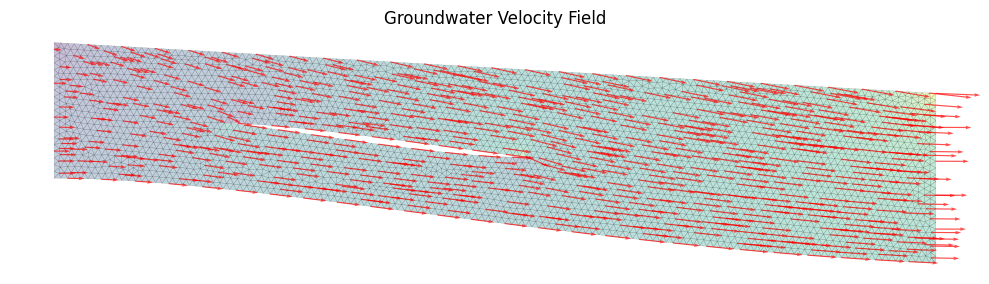

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import sparse
import os
from urllib.request import urlretrieve

# import local py-files
import postprocess as pp
import mesh_utils as mu

%matplotlib inline

# Download mesh and data files
def findfile(fname):
    if not os.path.isfile(fname):
        print(f"Downloading {fname}...")
        urlretrieve('https://github.com/TUDelft-MUDE/source-files/raw/main/file/GA2.2/'+fname, fname)

findfile('aquifer.msh')
findfile('velocity_elements.csv')

# Read mesh file
nodes, connectivity, edge_connectivity = mu.read_gmsh('aquifer.msh')

# Load velocity field on nodes and elements
velocities = np.loadtxt('velocity_elements.csv', delimiter=',')
pp.plot_velocity_field(nodes, connectivity, velocities)



## Finite element functions

The main building blocks for the finite element simulation are provided in the code block below. 

In [2]:
# Function makes the coefficients of shape functions for a 3-node triangle with given node coordinates
def get_shape_functions_T3(n1, n2, n3):
    coordinate_matrix = np.ones((3,3))
    coeffs = np.zeros((3,3))
    
    coordinate_matrix[0, 1] = n1[0]
    coordinate_matrix[0, 2] = n1[1]
    coordinate_matrix[1, 1] = n2[0]
    coordinate_matrix[1, 2] = n2[1]
    coordinate_matrix[2, 1] = n3[0]
    coordinate_matrix[2, 2] = n3[1]
    
    c_inv = np.linalg.inv(coordinate_matrix)
    coeffs[0] = np.dot(c_inv, (1,0,0))
    coeffs[1] = np.dot(c_inv, (0,1,0))
    coeffs[2] = np.dot(c_inv, (0,0,1))
    
    return coeffs

# Function creates the derivative shape function vector (B) of the given 3-node triangle
def get_B_matrix(n1, n2, n3):
    coeffs = get_shape_functions_T3(n1, n2, n3)
    B_matrix = [[coeffs[0][1], coeffs[1][1], coeffs[2][1]], 
                [coeffs[0][2], coeffs[1][2], coeffs[2][2]]]
    return np.array(B_matrix)

# Function returns the area of the triangle
def get_area(n1, n2, n3):
    u = n3-n1
    v = n2-n1
    return abs(u[0]*v[1]-u[1]*v[0])/2

# Evaluate shape function matrix at given coordinates
def evaluate_N_matrix(ipcoords, n1, n2, n3):    
    coeffs = get_shape_functions_T3(n1, n2, n3)
    x = ipcoords[0]
    y = ipcoords[1]
    N_matrix = [[coeffs[0][0] + coeffs[0][1]*x + coeffs[0][2]*y, 
                 coeffs[1][0] + coeffs[1][1]*x + coeffs[1][2]*y, 
                 coeffs[2][0] + coeffs[2][1]*x + coeffs[2][2]*y]]
    return np.array(N_matrix)

# DIFFUSION: Function returns the local K-matrix
def get_element_K(n1, n2, n3, nu):
    B = get_B_matrix(n1, n2, n3)
    element_area = get_area(n1, n2, n3)
    return element_area * nu * B.T @ B

# ADVECTION: Function returns the local C-matrix
# Advection matrix using simple integration (assumes constant velocity in element)
def get_element_C(n1, n2, n3, velocity):
    B = get_B_matrix(n1, n2, n3)
    element_area = get_area(n1, n2, n3)
    centroid = (n1 + n2 + n3) / 3
    N_centroid = evaluate_N_matrix(centroid, n1, n2, n3)
    
    v_matrix = np.array(velocity).reshape((1,2))
    C_el = N_centroid.T @ v_matrix @ B * element_area
    
    return C_el

# REACTION: Function returns the local R-matrix (reaction)
def get_element_R(n1, n2, n3, reaction_rate):
    R_el = np.zeros((3,3))
    element_area = get_area(n1, n2, n3)    
    integration_locations = [(n1+n2)/2, (n2+n3)/2, (n3+n1)/2]
    integration_weights = [element_area/3, element_area/3, element_area/3]
    for x_ip, w_ip in zip(integration_locations, integration_weights):
        N_local = evaluate_N_matrix(x_ip, n1, n2, n3)
        R_el += N_local.T @ N_local * w_ip * reaction_rate
    return R_el

# MASS: Function returns the local M-matrix
def get_element_M(n1, n2, n3):
    M_el = np.zeros((3,3))
    element_area = get_area(n1, n2, n3)    
    integration_locations = [(n1+n2)/2, (n2+n3)/2, (n3+n1)/2]
    integration_weights = [element_area/3, element_area/3, element_area/3]
    for x_ip, w_ip in zip(integration_locations, integration_weights):
        N_local = evaluate_N_matrix(x_ip, n1, n2, n3)
        M_el += N_local.T @ N_local * w_ip
    return M_el

# Assembly functions
def get_global_K(nodes, connectivity, nu):
    n_DOF = len(nodes)
    K = np.zeros((n_DOF, n_DOF))
    for elnodes in connectivity:
        K_el = get_element_K(nodes[elnodes[0]], nodes[elnodes[1]], nodes[elnodes[2]], nu)
        K[np.ix_(elnodes,elnodes)] += K_el
    return K

def get_global_C(nodes, connectivity, velocities):
    n_DOF = len(nodes)
    C = np.zeros((n_DOF, n_DOF))
    for elnodes, element_velocity in zip(connectivity, velocities):
        C_el = get_element_C(nodes[elnodes[0]], nodes[elnodes[1]], nodes[elnodes[2]], element_velocity)
        C[np.ix_(elnodes,elnodes)] += C_el
    return C

def get_global_R(nodes, connectivity, reaction_rate):
    n_DOF = len(nodes)
    R = np.zeros((n_DOF, n_DOF))
    for elnodes in connectivity:
        R_el = get_element_R(nodes[elnodes[0]], nodes[elnodes[1]], nodes[elnodes[2]], reaction_rate)
        R[np.ix_(elnodes,elnodes)] += R_el
    return R

def get_global_M(nodes, connectivity):
    n_DOF = len(nodes)
    M = np.zeros((n_DOF, n_DOF))
    for elnodes in connectivity:
        M_el = get_element_M(nodes[elnodes[0]], nodes[elnodes[1]], nodes[elnodes[2]])
        M[np.ix_(elnodes,elnodes)] += M_el
    return M

def get_global_f(nodes, elems, q, xmin=-1e6, xmax=1e6):
    n_DOF = len(nodes)
    f = np.zeros(n_DOF)
    for elem in elems:
        xcentroid = ( nodes[elem[0]][0] + nodes[elem[1]][0] ) / 2
        if xcentroid > xmin and xcentroid < xmax:
            length = np.linalg.norm(nodes[elem[0]]-nodes[elem[1]])
            f[elem] += q*length/2
    return f


## Solve the time-dependent advection-diffusion-reaction problem

Euler backward time integration gives the following linear system of equations for solving $\mathbf{c}$ at $t=t_{n+1}$

$$ 
\left(\frac{1}{\Delta t} \mathbf{M}  + \mathbf{K} + \mathbf{C} + \mathbf{R} \right) \mathbf{c}_{n+1} = \frac{1}{\Delta t} \mathbf{M} \mathbf{c}_{n} + \mathbf{f}_{n+1}
$$ 

The system of equations is rewritten as

$$
\mathbf{K}^\mathrm{mod} \mathbf{c}_{n+1} = \mathbf{f}^\mathrm{mod}_{n+1}
$$

which is solved in a loop over $n_t$ time steps. Because the system of equations needs to be solved $n_t$ times, each time with the same matrix $\mathbf{K^\mathrm{mod}}$ but a different right hand side vector $\mathbf{f}^\mathrm{mod}_{n+1}$, we use a two step approach for solving the system of equation. 

A system of equations $\mathbf{Ax}=\mathbf{b}$ can be solved in python in two lines as

```
  solver = sparse.linalg.factorized(A)
  x = solver(b)
```

Where the first line does most of the work associated with solving the system of equations, similar to but still cheaper than inverting the matrix. In our case, the first (expensive) line can be done outside of the loop over time steps, after which the second (cheap) line is all that needs to be done inside the loop. 

In [3]:
dt = 50      # Time step size in days
nt = 3000    # Number of time steps

def simulate ( dt_days = dt,             # Time step size [days]
               nt = nt,                  # Number of time steps
               diffusivity = 5e-7,       # Diffusion coefficient [m^2/s]
               reaction_rate = 1e-9,     # Reaction rate [1/s]
               q_max = 2e-9,             # Maximum boundary flux [kg/m^2/s]
               C_initial = 0,            # Initial concentration [kg/m^3]
               period = 25000,           # Spill duration [days]
               source_bounds = [50, 80]  # Position of the spill [m]
             ):

    dt = dt_days*60*60*24   # Time step size in seconds

    # Find constrained nodes
    constrained_nodes = []
    free_nodes = []
    min_x = min(nodes[:, 0])
    max_x = max(nodes[:, 0])
    for i in range(len(nodes)):
        if abs( nodes[i, 0] - min_x ) < 1.e-5:
            constrained_nodes.append(i)
        else:
            free_nodes.append(i)

    # Initialize solution array
    n_DOF = len(nodes)
    concentrations = np.zeros((nt+1, n_DOF))
    concentrations[0] = C_initial

    # Assemble all matrices
    K = sparse.csc_matrix(get_global_K(nodes, connectivity, diffusivity))
    C = sparse.csc_matrix(get_global_C(nodes, connectivity, velocities))
    R = sparse.csc_matrix(get_global_R(nodes, connectivity, reaction_rate))
    M = sparse.csc_matrix(get_global_M(nodes, connectivity))

    # Modified system matrix for time-discretized ADR problem
    Kmod = M/dt + K + C + R
    Kmodff = Kmod[np.ix_(free_nodes, free_nodes)]

    # Pre-factorize
    solver = sparse.linalg.factorized(Kmodff)

    # Time stepping
    for i in range(nt):
        q_now = q_max*(1-np.cos(2*np.pi*min(i*dt_days,period)/period))/2
        f = get_global_f(nodes, edge_connectivity, q_now, source_bounds[0], source_bounds[1])

        concentrations[i+1, constrained_nodes] = 0
        fmod = M.dot(concentrations[i]) / dt + f
        fmodf = fmod[free_nodes]

        # Solve for free nodes: c = Kmodff^{-1} * fmodf
        concentrations[i+1, free_nodes] = solver(fmodf)

    return concentrations

In [4]:
# Run finite element simulation to compute concentrations over time
concentrations = simulate()

## Postprocess

Results can be visualized with functions from *postprocess.py*. Specifically, the function `plot_concentration_interactive` creates an interactive plot of how the contaminant concentration evolves over time. If the interactive plot does not work on your system, the simpler `plot_concentration` function can be used to inspect the results. 

In [5]:
# Two nodes are selected for sampling
measurement_nodes = [776, 1176]
for i in measurement_nodes:
    print(f'measurement node {i}, has coordinates {nodes[i][:2]}')

# Plot results in interactive plot, indicate 
pp.plot_concentration_interactive(nodes, connectivity, concentrations, highlight_nodes=measurement_nodes)

# Alternatively, uncomment this line to plot results for a specific time step
# pp.plot_concentration(nodes, connectivity, concentrations, highlight_nodes=measurement_nodes, step=3000)


measurement node 776, has coordinates [264.99521689   7.74940747]
measurement node 1176, has coordinates [267.69921057 -41.10992476]


Output()

<div style="background-color:#AABAB2; color: black; width:90%; vertical-align: middle; padding:15px; margin: 10px; border-radius: 10px">
<p>

<b>Task 2</b>

Inspect the code and results to see which boundary conditions are applied. 
- In which part of the code are Dirichlet boundary conditions applied? 
- In which part of the code are Neumann boundary conditions applied? 
- What are the effective boundary conditions for the parts of the boundaries on which the simulation does not do anything?  Motivate your answer with an observation about the simulation results.
- Give a mathematical expressions for the boundary conditions of the problem that is solved here.
</p>
</div>

<div style="background-color:#facb8e; color: black; vertical-align: middle; padding:15px; margin: 10px; border-radius: 10px; width: 90%">
<p>

$\text{Hint:}$

- Find relevant text in the book in [Section 2.4](https://mude.citg.tudelft.nl/book/2025/fem/matrix.html#boundary-conditions) and [Section 2.7](https://mude.citg.tudelft.nl/book/2025/fem/poisson2d.html)
- For your answer, you can refer to different boundaries in words, like "left boundary" and "top boundary", without needing to look up corresponding coordinates. Do specify which values are prescribed on the different boundaries.
- The matrix `edge_connectivity` in the code defines line elements along the top boundary of the domain only. 
</p>
</div>

<div style="background-color:#FAE99E; color: black; vertical-align: middle; padding:15px; margin: 10px; border-radius: 10px; width: 90%">
<p>
<b>Solution</b>


**In which part of the code are Dirichlet boundary conditions applied? Include the function, code line(s) and any parameters that need to be defined**

In the `simulate` function itself, when only the `[free_nodes,free_nodes]` part of the matrix is considered for solving the system of equations, while values for the `constrained_nodes` are set to 0. 

```
    Kmodff = Kmod[np.ix_(free_nodes, free_nodes)]
        :
        concentrations[i+1, constrained_nodes] = 0
```

The part where `constrained_nodes` are selected is also relevant but not essential. It is not where the boundary conditions are applied. 

**In which part of the code are Neumann boundary conditions applied? Include the function, code line(s) and any parameters that need to be defined**

In the `get_global_f` function

**What are the effective boundary conditions for the parts of the boundaries on which the simulation does not do anything?  Motivate your answer with an observation about the simulation results.** 

Homogeneous Neumann boundary conditions $q=0$. Observed by contours remaining normal to the boundary. 

**Give  a mathematical expression for the boundary conditions that are applied on the different boundaries of the domain**

$c=0$ at the left boundary

$q=0$ at the right boundary, bottom boundary and interior boundary

$q=1\cdot10^9\left(1+\cos\left(\frac{2\pi t}{25000}\right)\right)$ while $t<25000$ and $q=0$ afterwards at the top boundary for $x\in[50,80]$

$q=0$ at the remainder of the top boundary

</p>
</div>

<div style="background-color:#AABAB2; color: black; width:90%; vertical-align: middle; padding:15px; margin: 10px; border-radius: 10px">
<p>

<b>Task 3</b>

Investigate sensitivity of results to different input parameters. Specifically look at nodes 776 and 1176, which are indicated with markers in the interactive plot above. The cell below shows how local evolution of the concentration in these two points can be plotted. 
- What happens if you assume the contimant is inert by setting $r=0$?
- What happens if the diffusivity is reduced with a factor 10 (use the original value for $r$)?

In your answer to both questions, plot results and give a qualitative description of the influence of the changes in the input, focusing on when the local concentration reaches a maximum and how high the maximum concentration is. 
</p>
</div>

<div style="background-color:#facb8e; color: black; vertical-align: middle; padding:15px; margin: 10px; border-radius: 10px; width: 90%">
<p>

$\text{Hint:}$

You will need to rerun the simulation with new inputs. After calling the `simulate` function, the `plot_time_series` function can be used to plot the relevant results. 
</p>
</div>

<div style="background-color:#FAE99E; color: black; vertical-align: middle; padding:15px; margin: 10px; border-radius: 10px; width: 90%">
<p>
<b>Solution</b>


**What happens if you assume the contimant is inert by setting $r=0$?**

The peak is much higher (about ~100 and ~200 times for the two measurement nodes) and arrives later. With nonzero $r$ the peak is happening earlier because concentrations get reduced progressively over time. 


**What happens if the diffusivity is reduced with a factor 10 (use the original value for $r$)?**

For node 776 (closer to the surface) the peak is similar of similar height to that from the reference case. The peak arrives later. Reduced diffusion keeps the contimanant cloud more concentrated, but because it takes longer for the contaminant to reach the measurement point, there is also more time for reactive decay. For the node 1176 (deeper underground) the peak is much lower. As the flow is mostly parallel to the water table and the spill is at the surface, diffusion is needed for the contaminant to reach depth. 

</p>
</div>

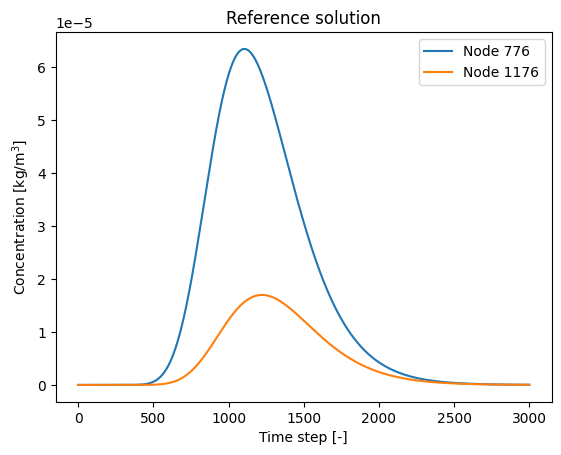

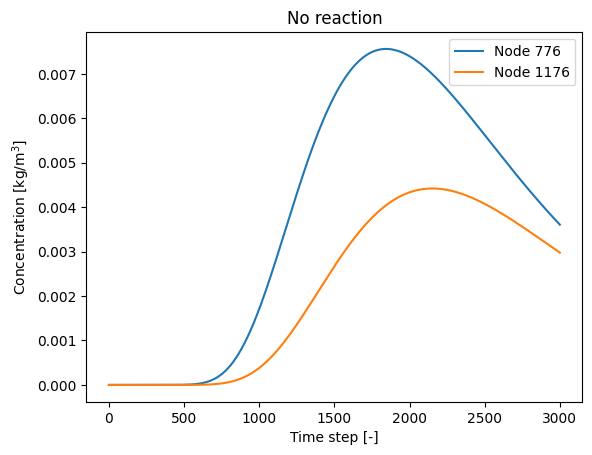

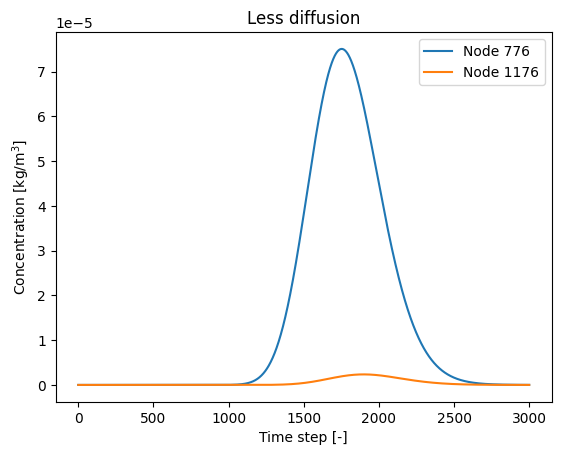

In [6]:
def plot_time_series(concentrations, nodes, title):
    plt.figure()
    for i in nodes:
        plt.plot(concentrations[:,i],label='Node '+str(i))
    plt.ylabel('Concentration [kg/m$^3$]')
    plt.xlabel('Time step [-]')
    plt.title(title)
    plt.legend()
    plt.show()

plot_time_series(concentrations, measurement_nodes, 'Reference solution')

no_reaction = simulate(reaction_rate=0)
plot_time_series(no_reaction, measurement_nodes, 'No reaction')

less_diffusion = simulate(diffusivity=5e-8)
plot_time_series(less_diffusion, measurement_nodes, 'Less diffusion')

## Groundwater flow: another FE problem

The groundwater flow field that is an input to the simulation above has also been computed with a finite element analysis, on the same mesh. The groundwater flow computation is a two-step procedure. The first step is to solve a stationary problem for the hydraulic head. The governing equation is 

$$
\nabla\cdot\left(\alpha\nabla h\right) = 0
$$

where $\alpha$ is the hydraulic conductivity and $h$ is the hydraulic head. In the simulation, we assume that the water table is known and coincides with the top boundary of the mesh. The following boundary conditions apply:

$$
\begin{split}
h = h_\mathrm{left} &\quad\text{on the left boundary} \\
h = h_\mathrm{right} &\quad\text{on the right boundary} \\
\alpha\frac{\partial h}{\partial n} = f &\quad\text{on the top boundary} \\
\alpha\frac{\partial h}{\partial n} = 0 &\quad\text{on other boundaries}
\end{split}
$$

where $h_\mathrm{left}$, $h_\mathrm{right}$ and $f$ are given constants. The difference in hydraulic head $h_\mathrm{left}-h_\mathrm{right}$ drives the groundwater flow and $f$ is a constant infiltration rate. 

After solving this boundary value problem for $h(x,y)$, the second step is to compute the groundwater velocity with Darcy's law: 

$$
\mathbf{v} = -\frac{\alpha}{\mu}\nabla h
$$

where $\mathbf{v}$ is the velocity vector field and $\mu$ is the porosity. 


<div style="background-color:#AABAB2; color: black; width:90%; vertical-align: middle; padding:15px; margin: 10px; border-radius: 10px">
<p>

<b>Task 4</b>

Describe the finite element formulation needed to solve the groundwater flow problem.
- If you want to code a `simulate` function to compute the hydraulic head distribution on the domain, which of the finite element functions in this notebook could you reuse? 
- How would you deal with the boundary conditions for this problem? 
- In this notebook, we have used velocity vectors inside each element. After solving for $h$ on the nodes, how would you compute the velocity at the center of a given element in the mesh? The correct answer here involves the finite element shape functions.

</p>
</div>

<div style="background-color:#facb8e; color: black; vertical-align: middle; padding:15px; margin: 10px; border-radius: 10px; width: 90%">
<p>

**For the brave:**

If you have time left and want to check whether your strategy makes sense, you can try to implement the procedures. 

For preparing the data file, we specified boundary conditions as $h_\mathrm{left}=50$ m, $h_\mathrm{right}=20$ m and $f = 10^{-9}$ m/s. Parameters were set to $\mu=0.2$ and $\alpha=10^{-7}$ m/s. 

Note the `postprocess.py` module also has a function `plot_head_contours` that can be used to visualize results from the first step  of the analysis.

</p>
</div>

<div style="background-color:#FAE99E; color: black; vertical-align: middle; padding:15px; margin: 10px; border-radius: 10px; width: 90%">
<p>
<b>Solution</b>

**If you want to code a `simulate` function to compute the hydraulic head distribution on the domain, which of the finite element functions in this notebook could you reuse?**

The `simulate` function can use `get_global_K` and `get_global_f` in unmodified form. 

**How would you deal with the boundary conditions for this problem?**

Neumann boundary conditions should be passed to the `get_global_f` function. Nonzero Dirichlet boundary conditions need to be applied by modifying the right-hand side vector when eliminating the degrees of freedom on which $h$ is prescribed. 

**In this notebook, we have used velocity vectors inside each element. After solving for $h$ on the nodes, how would you compute the velocity at the center of a given element in the mesh? The correct answer here involves the finite element shape functions.**

In every element, we can evaluate the $\mathbf{B}$ matrix with the derivative of the finite element shape functions. We can then compute $\nabla h=\mathbf{B} \mathbf{h}_\mathrm{elem}$ where $\mathbf{h}_\mathrm{elem}$ contains the three nodal values of $h$ for the element. Finally, we can use 

$$v=-(\alpha/\mu)\nabla h $$

to compute the velocity. For a given element with nodes `elnodes` and nodal coordinates `n1`, `n2` and `n3` all this could be done in one line as:

```
v_local = -alpha / porosity * getBMatrix(n1, n2, n3) @ head[elnodes]
```

See solution notebook for a complete implementation. 

</p>
</div>

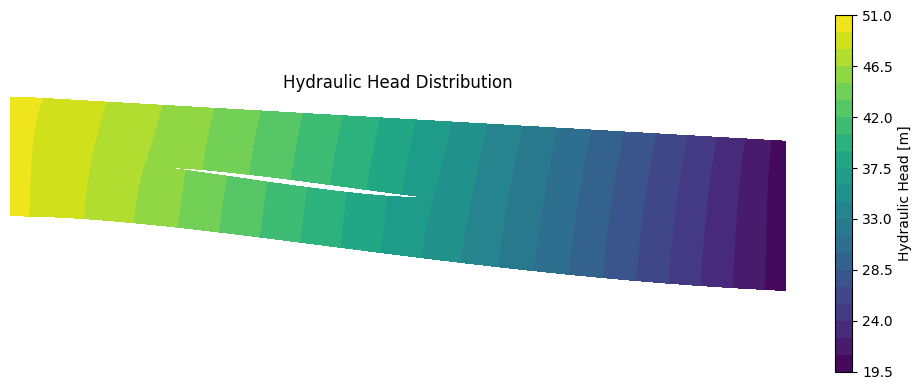

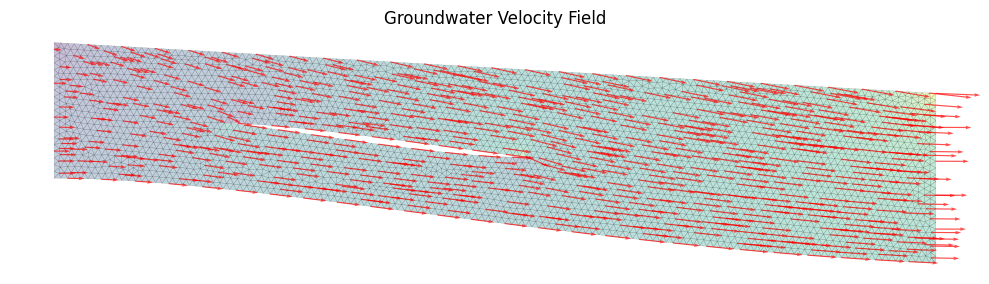

In [7]:
def solve_groundwater_flow(nodes, connectivity, head_left, head_right, K_hydraulic, infiltration_rate):
    n_DOF = len(nodes)
    
    # Assemble matrix
    K_flow = get_global_K(nodes, connectivity, K_hydraulic)
    
    # Find surface edges and apply infiltration (on whole top edge)
    f = get_global_f(nodes, edge_connectivity, infiltration_rate )
    
    # Find constrained nodes
    left_nodes = []
    right_nodes = []
    free_nodes = []
    min_x = min(nodes[:,0])
    max_x = max(nodes[:,0])
    for i in range(len(nodes)):
        if abs(nodes[i,0] - min_x) < 1.e-5:
            left_nodes.append(i)
        elif abs(nodes[i,0] - max_x) < 1.e-5:
            right_nodes.append(i)
        else:
            free_nodes.append(i)

    head_bc_values = [head_left] * len(left_nodes) + [head_right] * len(right_nodes)
    constrained_nodes = left_nodes + right_nodes

    # Select submatrices and solve
    K_ff = K_flow[np.ix_(free_nodes, free_nodes)]
    K_fp = K_flow[np.ix_(free_nodes, constrained_nodes)]
    f_f = f[free_nodes] - K_fp.dot(head_bc_values)
    
    head = np.zeros(n_DOF)
    head[constrained_nodes] = head_bc_values
    head[free_nodes] = np.linalg.solve(K_ff, f_f)
    
    return head

def compute_darcy_velocity(nodes, connectivity, head, K_hydraulic, porosity):
    n_elem = len(connectivity)
    velocities = np.zeros((n_elem, 2))
    
    for i, elnodes in enumerate(connectivity):
        n1, n2, n3 = nodes[elnodes[0]], nodes[elnodes[1]], nodes[elnodes[2]]
        
        # Get gradient matrix B
        B = get_B_matrix(n1, n2, n3)
        
        # Head gradient at element centroid
        h_element = head[elnodes]
        grad_h = B.dot(h_element)
        
        # Compute Darcy velocity
        velocities[i] = -K_hydraulic / porosity * grad_h
    
    return velocities

# Perform analysis

head_left = 50
head_right = 20
K_hydraulic = 1.e-7
recharge = 1.e-9
porosity = 0.2

head = solve_groundwater_flow(nodes, connectivity, head_left, head_right, K_hydraulic, recharge )
velocities = compute_darcy_velocity(nodes, connectivity, head, K_hydraulic, porosity )

# Plot results

pp.plot_head_contours(nodes, connectivity, head)
pp.plot_velocity_field(nodes, connectivity, velocities)

> By Frans van der Meer, Delft University of Technology. CC BY 4.0, more info on the Credits page of Workbook. 